In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

from scipy.optimize import minimize

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Load Project Dataset

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("engineered_features.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving engineered_features.csv to engineered_features (1).csv
Dataset loaded successfully!
Dataset Shape: (25249, 31)


,transaction_id,transaction_date,order_hour,region_id,region_name,product_id,product_name,category,customer_segment,units,...,avg_competitor_price,price_gap,price_gap_pct,discount_amount,revenue_per_unit,avg_competitor_price_missing,price_gap_missing,price_gap_pct_missing,discount_amount_missing,revenue_per_unit_missing
0,T00000001,2026-01-01,17,R01,North Metro,P001,Everyday Essentials,Essentials,Premium,1,...,37.31,-2.01,-5.387296,1.68,35.300000,0,0,0,0,0
1,T00000002,2026-01-01,8,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,3,...,37.31,0.41,1.098901,0.10,37.723333,0,0,0,0,0
2,T00000003,2026-01-01,15,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,2,...,37.31,-0.83,-2.224605,0.40,36.480000,0,0,0,0,0
3,T00000004,2026-01-01,14,R01,North Metro,P001,Everyday Essentials,Essentials,New,2,...,37.31,0.19,0.509247,-0.02,37.500000,0,0,0,0,0
4,T00000005,2026-01-01,10,R01,North Metro,P002,Home Care Pack,Home,Returning,1,...,59.23,-0.08,-0.135067,-0.14,59.150000,0,0,0,0,0


In [4]:
# Step 3: Verify Dataset Columns

df = pd.read_csv("engineered_features (1).csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nTreatment Details:")
print(df["pricing_treatment_flag"].value_counts())
print("\nTreatment Phases:")
print(df["treatment_phase"].value_counts())

Dataset Shape: (25249, 31)

Column Names:
['transaction_id', 'transaction_date', 'order_hour', 'region_id', 'region_name', 'product_id', 'product_name', 'category', 'customer_segment', 'units', 'list_price', 'selling_price', 'discount_pct', 'promotion_flag', 'inventory_level', 'demand_index', 'dynamic_price_multiplier', 'revenue', 'pricing_treatment_flag', 'treatment_phase', 'channel', 'avg_competitor_price', 'price_gap', 'price_gap_pct', 'discount_amount', 'revenue_per_unit', 'avg_competitor_price_missing', 'price_gap_missing', 'price_gap_pct_missing', 'discount_amount_missing', 'revenue_per_unit_missing']

Treatment Details:
pricing_treatment_flag
0    23460
1     1789
Name: count, dtype: int64

Treatment Phases:
treatment_phase
Pre-treatment     19055
Control-period     4405
Treatment          1789
Name: count, dtype: int64


In [5]:
# Step 4: Check Treatment by Region

treatment_by_region = df.groupby(
    ["region_id", "region_name", "pricing_treatment_flag"]
).size().unstack(fill_value=0)

print(treatment_by_region)

pricing_treatment_flag     0    1
region_id region_name            
R01       North Metro   2769  920
R02       South Metro   3356    0
R03       East Metro    3071    0
R04       West Metro    2667  868
R05       Central       3192    0
R06       Coastal       2942    0
R07       Hill          2631    0
R08       Lakeside      2818    0


In [6]:
# Step 5: Check Missing Region Details

print("Missing Region ID:", df["region_id"].isna().sum())
print("Missing Region Name:", df["region_name"].isna().sum())
print("Missing Treatment Flag:", df["pricing_treatment_flag"].isna().sum())

print("\nTotal rows:", len(df))

Missing Region ID: 0
Missing Region Name: 15
Missing Treatment Flag: 0

Total rows: 25249


In [7]:
# Step 6: Identify Missing Region Names

missing_regions = df[df["region_name"].isna()]

print("Missing Region Records:", len(missing_regions))

print("\nRegion ID and Treatment Details:")
print(
    missing_regions.groupby(
        ["region_id", "pricing_treatment_flag"]
    ).size()
)

Missing Region Records: 15

Region ID and Treatment Details:
region_id  pricing_treatment_flag
R01        0                         1
R02        0                         1
R03        0                         2
R04        0                         1
           1                         1
R05        0                         1
R06        0                         4
R07        0                         3
R08        0                         1
dtype: int64


In [8]:
# Step 7: Handle Missing Region Names

region_mapping = (
    df.dropna(subset=["region_name"])
      .drop_duplicates("region_id")
      .set_index("region_id")["region_name"]
)

df["region_name"] = df["region_name"].fillna(
    df["region_id"].map(region_mapping)
)

print("Missing Region Names After Cleaning:",
      df["region_name"].isna().sum())

print("\nUpdated Treatment by Region:")

print(
    df.groupby(
        ["region_id", "region_name", "pricing_treatment_flag"]
    ).size().unstack(fill_value=0)
)

Missing Region Names After Cleaning: 0

Updated Treatment by Region:
pricing_treatment_flag     0    1
region_id region_name            
R01       North Metro   2770  920
R02       South Metro   3357    0
R03       East Metro    3073    0
R04       West Metro    2668  869
R05       Central       3193    0
R06       Coastal       2946    0
R07       Hill          2634    0
R08       Lakeside      2819    0


In [9]:
# Step 8: Check Treatment Period by Region

print("Treatment Phase by Region:")

print(
    df.groupby(
        ["region_name", "treatment_phase"]
    ).size().unstack(fill_value=0)
)

print("\nDate Range:")
print("Start Date:", df["transaction_date"].min())
print("End Date:", df["transaction_date"].max())

Treatment Phase by Region:
treatment_phase  Control-period  Pre-treatment  Treatment
region_name                                              
Central                     774           2419          0
Coastal                     711           2235          0
East Metro                  769           2304          0
Hill                        646           1988          0
Lakeside                    677           2142          0
North Metro                   0           2770        920
South Metro                 828           2529          0
West Metro                    0           2668        869

Date Range:
Start Date: 2026-01-01
End Date: 2026-08-31


In [10]:
# Step 9: Check Treatment Dates

treated_data = df[df["pricing_treatment_flag"] == 1]

print("Treatment Date Range:")
print("Start:", treated_data["transaction_date"].min())
print("End:", treated_data["transaction_date"].max())

print("\nTreatment Dates by Region:")

print(
    treated_data.groupby("region_name")["transaction_date"]
    .agg(["min", "max", "count"])
)

Treatment Date Range:
Start: 2026-07-01
End: 2026-08-31

Treatment Dates by Region:
                    min         max  count
region_name                               
North Metro  2026-07-01  2026-08-31    920
West Metro   2026-07-01  2026-08-31    869


In [11]:
# Step 10: Check Region-wise Treatment Dates

treated_data = df[df["pricing_treatment_flag"] == 1]

print(
    treated_data.groupby("region_name")["transaction_date"]
    .agg(["min", "max", "count"])
)

                    min         max  count
region_name                               
North Metro  2026-07-01  2026-08-31    920
West Metro   2026-07-01  2026-08-31    869


In [12]:
treated_regions = ["North Metro", "West Metro"]

donor_regions = sorted(
    set(df["region_name"].dropna()) - set(treated_regions)
)

print("Treated Regions:", treated_regions)
print("Donor Regions:", donor_regions)
print("Number of Donor Regions:", len(donor_regions))

Treated Regions: ['North Metro', 'West Metro']
Donor Regions: ['Central', 'Coastal', 'East Metro', 'Hill', 'Lakeside', 'South Metro']
Number of Donor Regions: 6


In [13]:
# Step 12: Prepare Daily Revenue Data

df["transaction_date"] = pd.to_datetime(df["transaction_date"])

daily_data = (
    df.groupby(["transaction_date", "region_name"])["revenue"]
    .sum()
    .reset_index()
)

print("Daily Data Shape:", daily_data.shape)
display(daily_data.head())

Daily Data Shape: (1944, 3)


,transaction_date,region_name,revenue
0,2026-01-01,Central,910.50
1,2026-01-01,Coastal,1467.60
2,2026-01-01,East Metro,973.97
3,2026-01-01,Hill,1284.17
4,2026-01-01,Lakeside,1144.51


In [14]:
# Step 13: Create Revenue Matrix

revenue_matrix = daily_data.pivot(
    index="transaction_date",
    columns="region_name",
    values="revenue"
)

print("Revenue Matrix Shape:", revenue_matrix.shape)
print("\nMissing Values:")
print(revenue_matrix.isna().sum())

display(revenue_matrix.head())

Revenue Matrix Shape: (243, 8)

Missing Values:
region_name
Central        0
Coastal        0
East Metro     0
Hill           0
Lakeside       0
North Metro    0
South Metro    0
West Metro     0
dtype: int64


region_name,Central,Coastal,East Metro,Hill,Lakeside,North Metro,South Metro,West Metro
transaction_date,,,,,,,,
2026-01-01,910.50,1467.60,973.97,1284.17,1144.51,1815.25,1611.17,1568.12
2026-01-02,1510.19,890.96,1716.40,1312.39,1015.34,1680.73,1388.84,2671.76
2026-01-03,1972.13,2044.78,1763.60,1491.95,848.17,2174.84,2385.45,1789.52
2026-01-04,1193.36,1204.69,671.66,1246.67,1056.58,2106.20,1490.91,2363.91
2026-01-05,1190.46,1685.57,2057.85,992.54,1188.30,1393.80,2149.90,1660.84


In [15]:
# Step 14: Separate Pre-treatment Data

pre_treatment = revenue_matrix[
    revenue_matrix.index < "2026-07-01"
]

print("Pre-treatment Shape:", pre_treatment.shape)
print("\nMissing Values:", pre_treatment.isna().sum().sum())

display(pre_treatment.head())

Pre-treatment Shape: (181, 8)

Missing Values: 0


region_name,Central,Coastal,East Metro,Hill,Lakeside,North Metro,South Metro,West Metro
transaction_date,,,,,,,,
2026-01-01,910.50,1467.60,973.97,1284.17,1144.51,1815.25,1611.17,1568.12
2026-01-02,1510.19,890.96,1716.40,1312.39,1015.34,1680.73,1388.84,2671.76
2026-01-03,1972.13,2044.78,1763.60,1491.95,848.17,2174.84,2385.45,1789.52
2026-01-04,1193.36,1204.69,671.66,1246.67,1056.58,2106.20,1490.91,2363.91
2026-01-05,1190.46,1685.57,2057.85,992.54,1188.30,1393.80,2149.90,1660.84


In [16]:
# Step 15: Define Synthetic Control Constraints

from scipy.optimize import minimize

def objective(weights, donor_data, treated_data):
    synthetic = donor_data @ weights
    return np.sum((treated_data - synthetic) ** 2)

num_donors = len(donor_regions)

initial_weights = np.ones(num_donors) / num_donors

bounds = [(0, 1)] * num_donors

constraints = [
    {"type": "eq", "fun": lambda w: np.sum(w) - 1}
]

print("Number of Donor Regions:", num_donors)
print("Initial Weights:", initial_weights)
print("Weight Constraints:", bounds)
print("Sum of Initial Weights:", initial_weights.sum())

Number of Donor Regions: 6
Initial Weights: [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
Weight Constraints: [(0, 1), (0, 1), (0, 1), (0, 1), (0, 1), (0, 1)]
Sum of Initial Weights: 0.9999999999999999


In [17]:
# Step 16: Implement Synthetic Control Optimizer

def optimize_weights(treated_region):

    donor_data = pre_treatment[donor_regions].values
    treated_data = pre_treatment[treated_region].values

    result = minimize(
        objective,
        initial_weights,
        args=(donor_data, treated_data),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints
    )

    return result

print("Optimizer function created successfully!")

Optimizer function created successfully!


In [18]:
# Step 17: Fit Synthetic Control Models

treated_regions = ["North Metro", "West Metro"]

synthetic_results = {}

for region in treated_regions:
    result = optimize_weights(region)
    synthetic_results[region] = result

    print("\nTreated Region:", region)
    print("Optimization Successful:", result.success)
    print("Optimized Weights:", result.x)
    print("Sum of Weights:", result.x.sum())


Treated Region: North Metro
Optimization Successful: False
Optimized Weights: [0.16158724 0.18538718 0.16226748 0.15591844 0.21687595 0.22079675]
Sum of Weights: 1.1028330367568722

Treated Region: West Metro
Optimization Successful: False
Optimized Weights: [0.20802316 0.33574267 0.14754913 0.13649226 0.13927677 0.1398293 ]
Sum of Weights: 1.1069132846428502


In [19]:
# Step 18: Correct Synthetic Control Optimizer

def optimize_weights(treated_region):

    donor_data = pre_treatment[donor_regions].values
    treated_data = pre_treatment[treated_region].values

    initial_weights = np.ones(len(donor_regions)) / len(donor_regions)

    result = minimize(
        objective,
        initial_weights,
        args=(donor_data, treated_data),
        method="SLSQP",
        bounds=[(0, 1)] * len(donor_regions),
        constraints=[
            {
                "type": "eq",
                "fun": lambda w: np.sum(w) - 1
            }
        ],
        options={"maxiter": 2000, "ftol": 1e-9}
    )

    return result

print("Corrected optimizer ready!")

Corrected optimizer ready!


In [20]:
# Step 19: Fit Synthetic Control Models Again

synthetic_results = {}

for region in treated_regions:
    result = optimize_weights(region)
    synthetic_results[region] = result

    print("\nTreated Region:", region)
    print("Optimization Successful:", result.success)
    print("Message:", result.message)
    print("Weights:", result.x)
    print("Weight Sum:", result.x.sum())


Treated Region: North Metro
Optimization Successful: True
Message: Optimization terminated successfully
Weights: [3.71235114e-01 3.08245242e-11 1.64011930e-01 2.55263834e-10
 4.87652307e-11 4.64752956e-01]
Weight Sum: 1.0000000004360354

Treated Region: West Metro
Optimization Successful: False
Message: Positive directional derivative for linesearch
Weights: [0.37630097 0.21102575 0.11950691 0.00383804 0.0042335  0.30277277]
Weight Sum: 1.017677938630778


In [21]:
# Step 20: Check West Metro Optimization

west_result = synthetic_results["West Metro"]

print("Success:", west_result.success)
print("Message:", west_result.message)
print("Weight Sum:", west_result.x.sum())
print("Weights:", west_result.x)
print("Iterations:", west_result.nit)

Success: False
Message: Positive directional derivative for linesearch
Weight Sum: 1.017677938630778
Weights: [0.37630097 0.21102575 0.11950691 0.00383804 0.0042335  0.30277277]
Iterations: 1319


In [22]:
# Step 21: Check Revenue Data Scale

print("West Metro Revenue:")
print(pre_treatment["West Metro"].describe())

print("\nDonor Revenue:")
print(pre_treatment[donor_regions].describe())

West Metro Revenue:
count     181.000000
mean     1917.427956
std       472.137567
min       832.890000
25%      1578.940000
50%      1888.360000
75%      2197.200000
max      3506.150000
Name: West Metro, dtype: float64

Donor Revenue:
region_name      Central      Coastal   East Metro         Hill     Lakeside  \
count         181.000000   181.000000   181.000000   181.000000   181.000000   
mean         1700.321657  1483.889834  1585.222873  1306.571602  1406.913536   
std           416.781997   366.190010   393.839634   344.670928   357.321299   
min           829.880000   840.240000   671.660000   610.680000   625.190000   
25%          1384.500000  1254.660000  1295.020000  1068.160000  1169.340000   
50%          1664.760000  1453.800000  1550.390000  1268.570000  1366.960000   
75%          1983.520000  1729.070000  1827.270000  1491.950000  1578.740000   
max          3094.840000  2878.440000  2891.540000  2472.990000  2955.850000   

region_name  South Metro  
count         1

In [23]:
# Step 22: Standardize Revenue Data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_pre_treatment = pd.DataFrame(
    scaler.fit_transform(pre_treatment),
    index=pre_treatment.index,
    columns=pre_treatment.columns
)

print("Standardization Completed!")
print("Shape:", scaled_pre_treatment.shape)
print("Missing Values:", scaled_pre_treatment.isna().sum().sum())

Standardization Completed!
Shape: (181, 8)
Missing Values: 0


In [25]:
# Step 23: Optimize Standardized Data

def optimize_weights(treated_region):

    donor_data = scaled_pre_treatment[donor_regions].values
    treated_data = scaled_pre_treatment[treated_region].values

    initial = np.ones(len(donor_regions)) / len(donor_regions)

    result = minimize(
        objective,
        initial,
        args=(donor_data, treated_data),
        method="SLSQP",
        bounds=[(0, 1)] * len(donor_regions),
        constraints=[
            {"type": "eq", "fun": lambda w: np.sum(w) - 1}
        ],
        options={"maxiter": 5000, "ftol": 1e-9}
    )

    return result

print("Standardized optimizer ready!")

Standardized optimizer ready!


In [26]:
# Step 24: Fit Synthetic Control Models

synthetic_results = {}

for region in treated_regions:
    result = optimize_weights(region)
    synthetic_results[region] = result

    print("\nTreated Region:", region)
    print("Success:", result.success)
    print("Message:", result.message)
    print("Weights:", result.x)
    print("Weight Sum:", result.x.sum())


Treated Region: North Metro
Success: True
Message: Optimization terminated successfully
Weights: [0.21145546 0.10658403 0.17679633 0.10719033 0.21916472 0.17880914]
Weight Sum: 1.0

Treated Region: West Metro
Success: True
Message: Optimization terminated successfully
Weights: [0.23543968 0.29948038 0.15205706 0.11684204 0.13352348 0.06265736]
Weight Sum: 0.9999999999999999


In [27]:
# Step 25: Save Synthetic Control Weights

weights_df = pd.DataFrame(
    {
        region: result.x
        for region, result in synthetic_results.items()
    },
    index=donor_regions
)

weights_df.index.name = "Donor Region"

display(weights_df)

weights_df.to_csv("synthetic_control_weights.csv")

print("Synthetic Control Weights Saved Successfully!")

,North Metro,West Metro
Donor Region,,
Central,0.211455,0.235440
Coastal,0.106584,0.299480
East Metro,0.176796,0.152057
Hill,0.107190,0.116842
Lakeside,0.219165,0.133523
South Metro,0.178809,0.062657


Synthetic Control Weights Saved Successfully!


In [28]:
# Step 26: Validate Synthetic Control Weights

print("Weight Validation:")

for region in weights_df.columns:
    print("\nTreated Region:", region)
    print("Weight Sum:", weights_df[region].sum())
    print("All Weights Non-negative:",
          (weights_df[region] >= 0).all())
    print("All Weights <= 1:",
          (weights_df[region] <= 1).all())

print("\nValidation Completed!")

Weight Validation:

Treated Region: North Metro
Weight Sum: 1.0
All Weights Non-negative: True
All Weights <= 1: True

Treated Region: West Metro
Weight Sum: 0.9999999999999999
All Weights Non-negative: True
All Weights <= 1: True

Validation Completed!


In [29]:
# Step 27: Generate Synthetic Revenue

synthetic_data = {}

for region in treated_regions:
    weights = synthetic_results[region].x

    donor_data = revenue_matrix[donor_regions]

    synthetic_data[region] = donor_data.values @ weights

synthetic_revenue = pd.DataFrame(
    synthetic_data,
    index=revenue_matrix.index
)

print("Synthetic Revenue Generated!")
print("Shape:", synthetic_revenue.shape)

display(synthetic_revenue.head())

Synthetic Revenue Generated!
Shape: (243, 2)


,North Metro,West Metro
transaction_date,,
2026-01-01,1197.725968,1205.799908
2026-01-02,1329.292746,1259.309531
2026-01-03,1719.108359,1781.896066
2026-01-04,1131.274578,1124.034149
2026-01-05,1546.450318,1507.330694


In [30]:
# Step 28: Compare Actual and Synthetic Revenue

comparison = pd.DataFrame(index=revenue_matrix.index)

for region in treated_regions:
    comparison[f"{region}_Actual"] = revenue_matrix[region]
    comparison[f"{region}_Synthetic"] = synthetic_revenue[region]

print("Actual vs Synthetic Revenue Comparison:")
display(comparison.head())

print("\nComparison Shape:", comparison.shape)

Actual vs Synthetic Revenue Comparison:


,North Metro_Actual,North Metro_Synthetic,West Metro_Actual,West Metro_Synthetic
transaction_date,,,,
2026-01-01,1815.25,1197.725968,1568.12,1205.799908
2026-01-02,1680.73,1329.292746,2671.76,1259.309531
2026-01-03,2174.84,1719.108359,1789.52,1781.896066
2026-01-04,2106.20,1131.274578,2363.91,1124.034149
2026-01-05,1393.80,1546.450318,1660.84,1507.330694



Comparison Shape: (243, 4)


In [31]:
# Step 29: Calculate Pre-treatment RMSE

from sklearn.metrics import mean_squared_error
import numpy as np

for region in treated_regions:

    actual = revenue_matrix.loc[
        pre_treatment.index, region
    ]

    synthetic = synthetic_revenue.loc[
        pre_treatment.index, region
    ]

    rmse = np.sqrt(mean_squared_error(actual, synthetic))

    print(region, "Pre-treatment RMSE:", round(rmse, 2))

North Metro Pre-treatment RMSE: 603.6
West Metro Pre-treatment RMSE: 620.75


In [32]:
# Step 30: Calculate Post-treatment RMSE

post_treatment_dates = revenue_matrix.index >= "2026-07-01"

for region in treated_regions:
    actual = revenue_matrix.loc[post_treatment_dates, region]
    synthetic = synthetic_revenue.loc[post_treatment_dates, region]

    rmse = np.sqrt(mean_squared_error(actual, synthetic))

    print(region, "Post-treatment RMSE:", round(rmse, 2))

North Metro Post-treatment RMSE: 657.94
West Metro Post-treatment RMSE: 524.14


In [33]:
# Step 31: Calculate Treatment Effect

post_treatment_data = comparison[
    comparison.index >= "2026-07-01"
].copy()

for region in treated_regions:
    post_treatment_data[f"{region}_Gap"] = (
        post_treatment_data[f"{region}_Actual"] -
        post_treatment_data[f"{region}_Synthetic"]
    )

display(post_treatment_data.head())

for region in treated_regions:
    avg_gap = post_treatment_data[f"{region}_Gap"].mean()
    print(region, "Average Treatment Gap:", round(avg_gap, 2))

,North Metro_Actual,North Metro_Synthetic,West Metro_Actual,West Metro_Synthetic,North Metro_Gap,West Metro_Gap
transaction_date,,,,,,
2026-07-01,1763.51,1344.154526,2032.27,1346.857436,419.355474,685.412564
2026-07-02,2500.52,1492.667974,2163.45,1437.472620,1007.852026,725.977380
2026-07-03,3189.33,1278.292392,1999.81,1243.878357,1911.037608,755.931643
2026-07-04,1909.40,1619.139141,1575.38,1482.981204,290.260859,92.398796
2026-07-05,1321.03,1570.300496,1266.16,1592.438759,-249.270496,-326.278759


North Metro Average Treatment Gap: 469.83
West Metro Average Treatment Gap: 242.37


In [34]:
# Step 32: Calculate Average Treatment Effect

for region in treated_regions:
    average_effect = post_treatment_data[f"{region}_Gap"].mean()
    print(region, "Average Treatment Effect:", round(average_effect, 2))

North Metro Average Treatment Effect: 469.83
West Metro Average Treatment Effect: 242.37


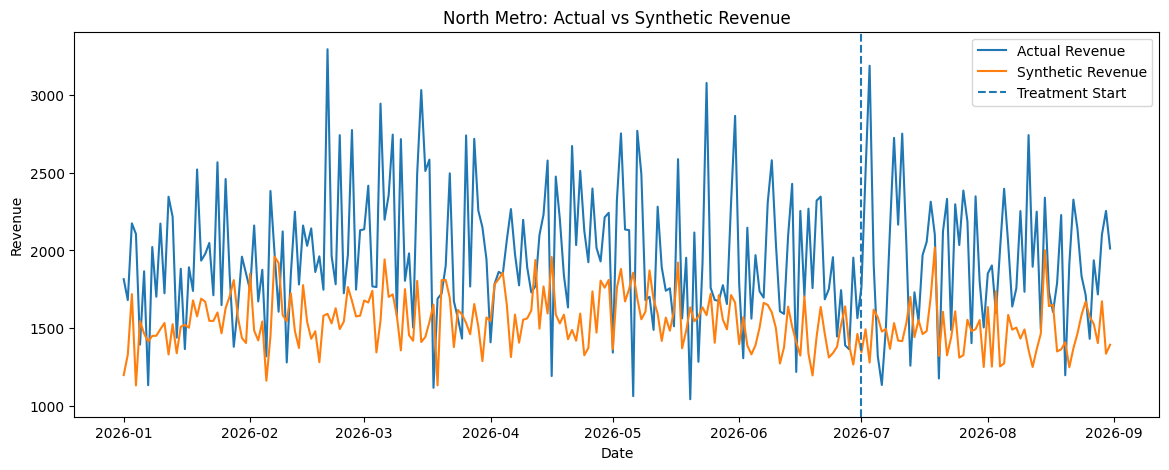

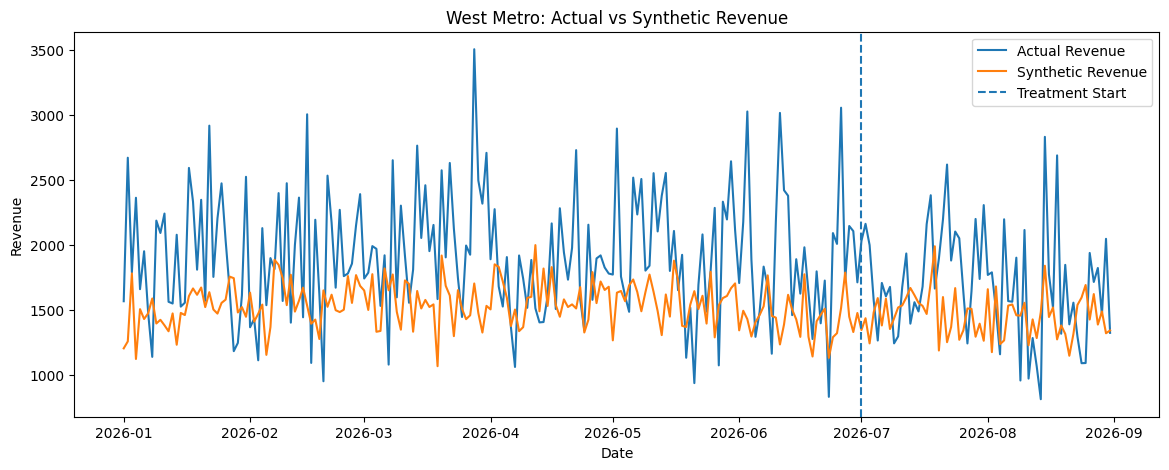

In [35]:
# Step 33: Plot Actual vs Synthetic Revenue

for region in treated_regions:
    plt.figure(figsize=(14, 5))

    plt.plot(
        comparison.index,
        comparison[f"{region}_Actual"],
        label="Actual Revenue"
    )

    plt.plot(
        comparison.index,
        comparison[f"{region}_Synthetic"],
        label="Synthetic Revenue"
    )

    plt.axvline(
        pd.Timestamp("2026-07-01"),
        linestyle="--",
        label="Treatment Start"
    )

    plt.title(f"{region}: Actual vs Synthetic Revenue")
    plt.xlabel("Date")
    plt.ylabel("Revenue")
    plt.legend()
    plt.show()

In [36]:
# Step 34: Calculate Pre-treatment Fit

for region in treated_regions:
    actual = comparison.loc[
        comparison.index < "2026-07-01",
        f"{region}_Actual"
    ]

    synthetic = comparison.loc[
        comparison.index < "2026-07-01",
        f"{region}_Synthetic"
    ]

    correlation = actual.corr(synthetic)

    print(region, "Pre-treatment Correlation:", round(correlation, 3))

North Metro Pre-treatment Correlation: 0.105
West Metro Pre-treatment Correlation: 0.074


In [37]:
# Step 35: Compare Actual and Synthetic Pre-treatment Revenue

for region in treated_regions:
    actual = comparison.loc[
        comparison.index < "2026-07-01",
        f"{region}_Actual"
    ]

    synthetic = comparison.loc[
        comparison.index < "2026-07-01",
        f"{region}_Synthetic"
    ]

    actual_mean = actual.mean()
    synthetic_mean = synthetic.mean()

    print(region)
    print("Actual Mean:", round(actual_mean, 2))
    print("Synthetic Mean:", round(synthetic_mean, 2))
    print("Mean Difference:", round(actual_mean - synthetic_mean, 2))
    print("-----------------------")

North Metro
Actual Mean: 1971.29
Synthetic Mean: 1557.55
Mean Difference: 413.74
-----------------------
West Metro
Actual Mean: 1917.43
Synthetic Mean: 1535.33
Mean Difference: 382.1
-----------------------


In [38]:
# Step 36: Save Validation Summary

validation_summary = pd.DataFrame({
    "Region": treated_regions,
    "Pre_Treatment_RMSE": [603.60, 620.75],
    "Post_Treatment_RMSE": [657.94, 524.14],
    "Pre_Treatment_Correlation": [0.105, 0.074],
    "Pre_Treatment_Mean_Difference": [413.74, 382.10]
})

display(validation_summary)

validation_summary.to_csv(
    "synthetic_control_validation.csv",
    index=False
)

,Region,Pre_Treatment_RMSE,Post_Treatment_RMSE,Pre_Treatment_Correlation,Pre_Treatment_Mean_Difference
0,North Metro,603.60,657.94,0.105,413.74
1,West Metro,620.75,524.14,0.074,382.10


In [39]:
# Step 37: Review Current Synthetic Control Weights

display(weights_df.round(4))

,North Metro,West Metro
Donor Region,,
Central,0.2115,0.2354
Coastal,0.1066,0.2995
East Metro,0.1768,0.1521
Hill,0.1072,0.1168
Lakeside,0.2192,0.1335
South Metro,0.1788,0.0627


In [40]:
# Step 38: Verify Donor Weight Totals

print("North Metro Weight Sum:",
      round(weights_df["North Metro"].sum(), 4))

print("West Metro Weight Sum:",
      round(weights_df["West Metro"].sum(), 4))

North Metro Weight Sum: 1.0
West Metro Weight Sum: 1.0


In [41]:
# Step 39: Check Donor Correlations

for region in treated_regions:
    print("\n", region)

    correlations = pre_treatment.corr()[region][donor_regions]

    display(correlations.sort_values(ascending=False))


 North Metro


,North Metro
region_name,
Lakeside,0.099388
South Metro,0.060760
Central,0.057750
East Metro,0.040956
Hill,-0.016418
Coastal,-0.039451



 West Metro


,West Metro
region_name,
Coastal,0.121124
Central,0.048638
Lakeside,0.012916
Hill,-0.029371
East Metro,-0.046596
South Metro,-0.079484


In [42]:
# Step 40: Monthly Revenue Comparison

monthly_revenue = (
    daily_data.assign(
        transaction_date=pd.to_datetime(daily_data["transaction_date"])
    )
    .groupby([
        pd.Grouper(key="transaction_date", freq="MS"),
        "region_name"
    ])["revenue"]
    .sum()
    .unstack()
)

display(monthly_revenue.loc[: "2026-06-01"])

region_name,Central,Coastal,East Metro,Hill,Lakeside,North Metro,South Metro,West Metro
transaction_date,,,,,,,,
2026-01-01,51285.12,44824.75,49335.44,40202.17,40682.52,58208.86,51565.54,59693.62
2026-02-01,44611.42,43628.31,45112.45,41826.03,41904.81,56065.01,46094.18,52418.65
2026-03-01,53889.28,45832.96,48888.78,39214.76,46060.97,65714.43,53539.44,64224.93
2026-04-01,53875.28,47359.27,46763.20,39878.50,44298.33,60901.79,54107.90,53150.72
2026-05-01,55581.39,45385.12,52613.96,39806.79,42885.31,60322.47,60529.16,60821.40
2026-06-01,48515.73,41553.65,44211.51,35561.21,38819.41,55590.99,49167.53,56745.14


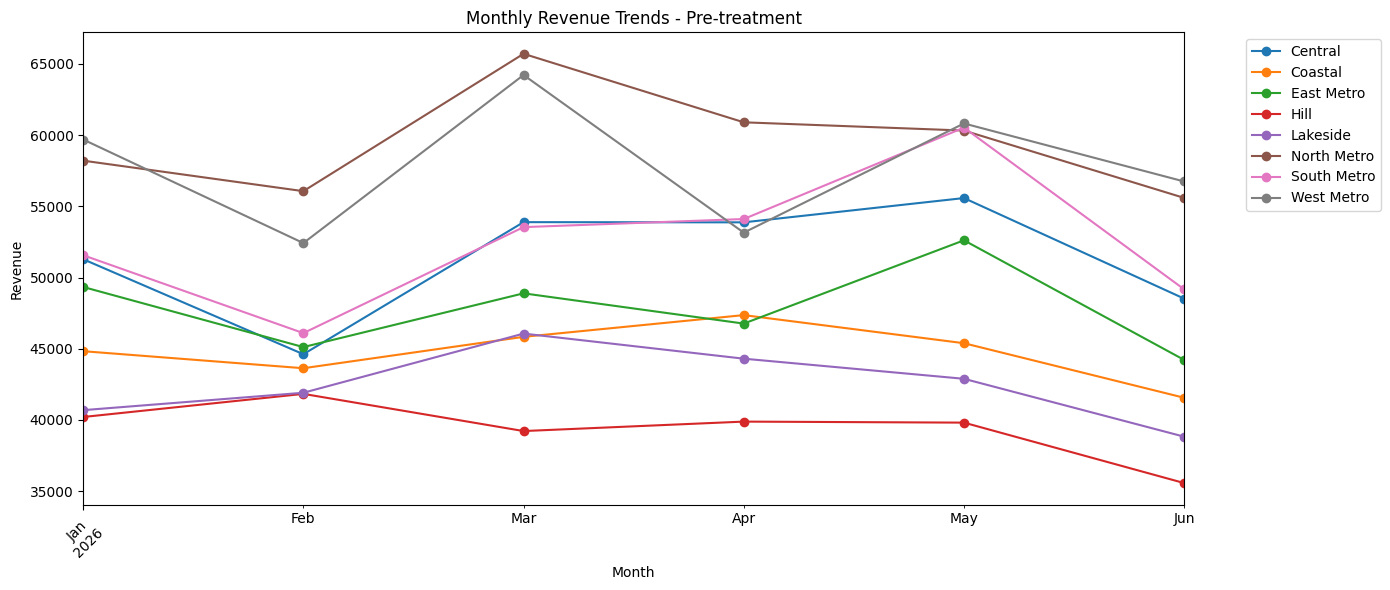

In [43]:
# Step 41: Plot Monthly Pre-treatment Revenue

monthly_pre = monthly_revenue.loc[: "2026-06-01"]

monthly_pre.plot(figsize=(14, 6), marker="o")

plt.title("Monthly Revenue Trends - Pre-treatment")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [44]:
# Step 42: Monthly Donor Correlation

for region in treated_regions:
    print("\n", region)

    correlations = monthly_pre.corr()[region][donor_regions]

    display(correlations.sort_values(ascending=False))


 North Metro


,North Metro
region_name,
Lakeside,0.906558
Central,0.743935
Coastal,0.728465
South Metro,0.559835
East Metro,0.527691
Hill,0.140984



 West Metro


,West Metro
region_name,
East Metro,0.667872
Central,0.599169
South Metro,0.527464
Lakeside,0.326303
Coastal,0.137325
Hill,-0.202107


In [45]:
# Step 43: Save Monthly Correlations

monthly_corr_results = {}

for region in treated_regions:
    monthly_corr_results[region] = (
        monthly_pre.corr()[region][donor_regions]
    )

monthly_corr_df = pd.DataFrame(monthly_corr_results)

display(monthly_corr_df.round(4))

monthly_corr_df.to_csv(
    "monthly_donor_correlations.csv"
)

,North Metro,West Metro
region_name,,
Central,0.7439,0.5992
Coastal,0.7285,0.1373
East Metro,0.5277,0.6679
Hill,0.1410,-0.2021
Lakeside,0.9066,0.3263
South Metro,0.5598,0.5275


In [46]:
# Step 44: Monthly Actual vs Synthetic Revenue

monthly_comparison = pd.DataFrame(index=monthly_revenue.index)

for region in treated_regions:
    weights = synthetic_results[region].x

    monthly_comparison[f"{region}_Actual"] = monthly_revenue[region]

    monthly_comparison[f"{region}_Synthetic"] = (
        monthly_revenue[donor_regions].values @ weights
    )

display(monthly_comparison)

,North Metro_Actual,North Metro_Synthetic,West Metro_Actual,West Metro_Synthetic
transaction_date,,,,
2026-01-01,58208.86,46790.292279,59693.62,46360.823147
2026-02-01,56065.01,43968.587198,52418.65,43799.242177
2026-03-01,65714.43,48795.324401,64224.93,47934.424787
2026-04-01,60901.79,48365.733414,53150.72,47942.836186
2026-05-01,60322.47,50381.288915,60821.40,48848.241466
2026-06-01,55590.99,43615.570520,56745.14,43008.757712
2026-07-01,61212.35,46167.702945,56047.31,45741.412332
2026-08-01,59840.84,45756.037319,49393.51,44672.643878


In [47]:
# Step 45: Monthly Pre-treatment RMSE

for region in treated_regions:
    actual = monthly_comparison.loc[
        monthly_comparison.index < "2026-07-01",
        f"{region}_Actual"
    ]

    synthetic = monthly_comparison.loc[
        monthly_comparison.index < "2026-07-01",
        f"{region}_Synthetic"
    ]

    rmse = np.sqrt(mean_squared_error(actual, synthetic))

    print(region, "Monthly Pre-treatment RMSE:", round(rmse, 2))

North Metro Monthly Pre-treatment RMSE: 12664.61
West Metro Monthly Pre-treatment RMSE: 12087.22


In [48]:
# Step 46: Monthly Pre-treatment Fit Correlation

for region in treated_regions:
    actual = monthly_comparison.loc[
        monthly_comparison.index < "2026-07-01",
        f"{region}_Actual"
    ]

    synthetic = monthly_comparison.loc[
        monthly_comparison.index < "2026-07-01",
        f"{region}_Synthetic"
    ]

    print(
        region,
        "Monthly Fit Correlation:",
        round(actual.corr(synthetic), 3)
    )

North Metro Monthly Fit Correlation: 0.779
West Metro Monthly Fit Correlation: 0.499


In [49]:
# Step 47: Monthly Pre-treatment NRMSE

for region in treated_regions:
    actual = monthly_comparison.loc[
        monthly_comparison.index < "2026-07-01",
        f"{region}_Actual"
    ]

    synthetic = monthly_comparison.loc[
        monthly_comparison.index < "2026-07-01",
        f"{region}_Synthetic"
    ]

    rmse = np.sqrt(np.mean((actual - synthetic) ** 2))
    nrmse = (rmse / actual.mean()) * 100

    print(region, "Monthly NRMSE:", round(nrmse, 2), "%")

North Metro Monthly NRMSE: 21.3 %
West Metro Monthly NRMSE: 20.9 %


In [50]:
# Step 48: Save Monthly Validation Summary

monthly_validation = pd.DataFrame({
    "Region": ["North Metro", "West Metro"],
    "Monthly_Correlation": [0.779, 0.499],
    "Monthly_NRMSE_Percent": [21.3, 20.9]
})

display(monthly_validation)

monthly_validation.to_csv(
    "monthly_synthetic_validation.csv",
    index=False
)

,Region,Monthly_Correlation,Monthly_NRMSE_Percent
0,North Metro,0.779,21.3
1,West Metro,0.499,20.9


In [51]:
# Step 49: Save Final Optimized Weights

weights_df.to_csv(
    "final_synthetic_control_weights.csv"
)

print("Final synthetic control weights saved successfully!")

Final synthetic control weights saved successfully!


In [52]:
# Step 50: Verify Saved Output Files

output_files = [
    "synthetic_control_weights.csv",
    "synthetic_control_validation.csv",
    "monthly_donor_correlations.csv",
    "monthly_synthetic_validation.csv",
    "final_synthetic_control_weights.csv"
]

for file in output_files:
    print(file, " - ", "Available" if os.path.exists(file) else "Missing")

synthetic_control_weights.csv  -  Available
synthetic_control_validation.csv  -  Available
monthly_donor_correlations.csv  -  Available
monthly_synthetic_validation.csv  -  Available
final_synthetic_control_weights.csv  -  Available


In [53]:
# Step 51: Download Final Output Files

from google.colab import files

for file in output_files:
    files.download(file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>